C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 44s 80ms/step - accuracy: 0.4724 - loss: 1.0153 - val_accuracy: 0.5488 - val_loss: 0.9232
Epoch 2/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 39s 74ms/step - accuracy: 0.5624 - loss: 0.9188 - val_accuracy: 0.6164 - val_loss: 0.8261
Epoch 3/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 39s 75ms/step - accuracy: 0.6119 - loss: 0.8403 - val_accuracy: 0.6472 - val_loss: 0.7839
Epoch 4/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 40s 76ms/step - accuracy: 0.6430 - loss: 0.7932 - val_accuracy: 0.6617 - val_loss: 0.7642
Epoch 5/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 45s 85ms/step - accuracy: 0.6585 - loss: 0.7636 - val_accuracy: 0.6793 - val_loss: 0.7218
Epoch 6/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.6759 - loss: 0.7244 - val_accuracy: 0.6996 - val_loss: 0.6868
Epoch 7/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.6911 - loss: 0.6972 - val_accuracy: 0.7105 - val_loss: 0.6681
Epoch 8/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 41s 78ms/step - accuracy: 0.7108 - loss: 0.6615 - 

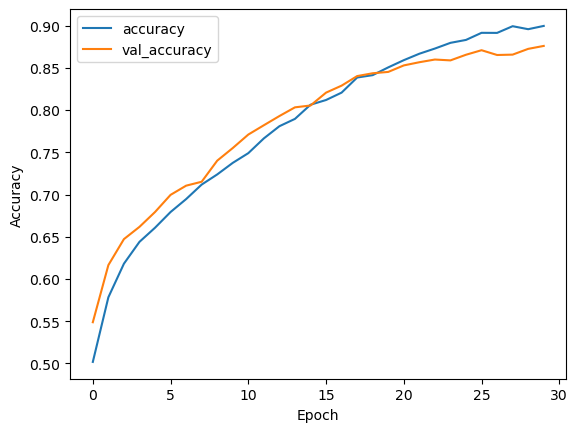

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# Define paths to train and test CSV files
train_csv_path = "fer2013.csv"
test_csv_path = "test.csv"

# Define emotion mapping (7 emotions → 3 stress classes)
emotion_map = {
    0: "High Stress",  # Angry
    1: "Low Stress",   # Disgust
    2: "High Stress",  # Fear
    3: "Low Stress",   # Happy
    4: "High Stress",  # Sad
    5: "Low Stress",   # Surprise
    6: "Neutral"       # Neutral
}

# Function to load and preprocess dataset
def load_data(csv_path):
    data = pd.read_csv(csv_path)
    data["emotion"] = data["emotion"].map(emotion_map)  # Map emotions to stress levels
    X = np.array([np.fromstring(image, sep=' ') for image in data["pixels"]])
    X = X / 255.0  # Normalize pixel values
    X = X.reshape(-1, 48, 48, 1)  # Reshape for CNN input
    y = np.array(data["emotion"])
    return X, y

# Load training and testing datasets
X_train, y_train = load_data(train_csv_path)
X_test, y_test = load_data(test_csv_path)

# Encode labels
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)
y_train = to_categorical(y_train, num_classes=3)
y_test = to_categorical(y_test, num_classes=3)

# Save label classes
np.save("fer_label_classes.npy", encoder.classes_)

# Build CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(48, 48, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')  # 3 output classes
])

# Compile model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, epochs=30, batch_size=64, validation_data=(X_test, y_test))

# Save model
model.save("fer_stress_model.h5")

# Plot training results
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
import joblib  # for saving the model

# Define emotion to stress mapping
emotion_map = {
    0: "High Stress",  # Angry
    1: "Low Stress",   # Disgust
    2: "High Stress",  # Fear
    3: "Low Stress",   # Happy
    4: "High Stress",  # Sad
    5: "Low Stress",   # Surprise
    6: "Neutral"       # Neutral
}

# Load and preprocess data
def load_data(csv_path):
    data = pd.read_csv(csv_path)
    data["emotion"] = data["emotion"].map(emotion_map)
    X = np.array([np.fromstring(image, sep=' ') for image in data["pixels"]])
    X = X / 255.0  # Normalize
    y = np.array(data["emotion"])
    return X, y

train_csv_path = "fer2013.csv"
test_csv_path = "test.csv"


# Load data
X_train, y_train = load_data(train_csv_path)
X_test, y_test = load_data(test_csv_path)

# Label encoding
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)
np.save("fer_label_classes_rf.npy", encoder.classes_)

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train_encoded)

# Predict and evaluate
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test_encoded, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test_encoded, y_pred, target_names=encoder.classes_))

# Save the model
joblib.dump(rf_model, "fer_stress_rf_model.pkl")

# Confusion matrix plot
conf_matrix = confusion_matrix(y_test_encoded, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(conf_matrix, cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.xticks(ticks=np.arange(3), labels=encoder.classes_)
plt.yticks(ticks=np.arange(3), labels=encoder.classes_)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'fer2013.csv'

In [2]:
pip install numpy pandas matplotlib scikit-learn joblib


     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     --------------------------------------- 0.0/12.9 MB 393.8 kB/s eta 0:00:33
     --------------------------------------- 0.1/12.9 MB 737.3 kB/s eta 0:00:18
      --------------------------------------- 0.2/12.9 MB 1.1 MB/s eta 0:00:12
      --------------------------------------- 0.3/12.9 MB 1.2 MB/s eta 0:00:11
     - -------------------------------------- 0.5/12.9 MB 1.9 MB/s eta 0:00:07
     -- ------------------------------------- 1.0/12.9 MB 3.0 MB/s eta 0:00:04
     ---- ----------------------------------- 1.3/12.9 MB 3.6 MB/s eta 0:00:04
     ------ --------------------------------- 2.2/12.9 MB 5.4 MB/s eta 0:00:02
     ---------- ----------------------------- 3.4/12.9 MB 7.5 MB/s eta 0:00:02
     -------------- ------------------------- 4.7/12.9 MB 9.4 MB/s eta 0:00:01
     ------------------ --------------------- 6.0/12.9 MB 10.9 M


[notice] A new release of pip is available: 23.0.1 -> 25.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
